<a href="https://colab.research.google.com/github/Ruzejjur/EIEF1E_cv/blob/main/EIEF1Ecv_01_Decision_trees.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# Decision Trees.

**Prepared by:**
- Aleksej Gaj- ([email](mailto:aleksejalex@gmail.com))
- Jurij Ružejnikov- ([email](mailto:ruzejnikov@pef.czu.cz))

## Decision tree
 - non-parametric supervised learning algorithm
 - used both for classification and regression tasks
 - consists of:
     - **nodes**- that represent features
     - **branches**- that represent decision rules
     - **leaf nodes**- that represent outcomes
 - **inputs**- are usually given by tuple (where each element is an atrbute used for classification)
 - **criteria:**- "best split" and homogenity

Example:

![https://www.ibm.com/content/dam/connectedassets-adobe-cms/worldwide-content/cdp/cf/ul/g/ce/ed/ICLH_Diagram_Batch_03_24A-AI-ML-DecisionTree.png](https://www.ibm.com/content/dam/connectedassets-adobe-cms/worldwide-content/cdp/cf/ul/g/ce/ed/ICLH_Diagram_Batch_03_24A-AI-ML-DecisionTree.png)

 - employs a 'divide and conquer' strategy by performing a greedy search to identify the optimal split points within a tree

 - the process is repeated in a top-down recursive manner


 - somewhat similiar to Galton's machine

![https://aleksejgaj.cz/imgsbin/dynr/galton_machine.png](https://aleksejgaj.cz/imgsbin/dynr/galton_machine.png)



Example from AIMA:

![example form AIMA](https://raw.githubusercontent.com/aimacode/aima-python/61d695b37c6895902081da1f37baf645b0d2658a/images/decisiontree_fruit.jpg)

## The algorithm (briefly)
1. **Start with all the data*- in the root node.

2. **Choose the best feature*- to split the data based on a criterion.

3. **Split the dataset*- into two or more groups based on the chosen feature's values.

4. **Repeat the process*- for each subgroup, selecting the best feature at each step.

5. **Stop when*- a stopping criterion is met (e.g., max depth is reached, all samples in a node belong to the same class, or no significant improvement is possible).

6. **Assign a final label*- to each leaf node: (classification - use the majority class, regression - use the average value)


# Classification criteria

## Gini Impurity

The Gini impurity $ G $ is a metric used to evaluate node homogeneity when training decision trees. For a dataset with $ C $ classes, $ G $ is calculated as:

$$G = \sum_{i=1}^{C} p_i (1-p_i) = 1 - \sum_{i=1}^{C} p_i^2$$

where:

- $ C $ is the total number of classes.
- $ p_i $ is the probability of an item belonging to class i in the node.

**Meaning:*- $ G $  models a two-step random process representing how often a randomly chosen element would be misclassified. You randomly select an item from the dataset. The probability of picking an item of class $ i $ equals its proportion, $p_i$. You assign a label to this item randomly, following the overall class distribution. You assign the correct label $i$ with probability $p_i$, and an incorrect label with probability $(1-p_i)$. The probability of selecting class $i$ and simultaneously misclassifying it is the product $p_i(1-p_i)$. Summing these independent probabilities across all $C$ classes yields the total expected error rate.

### Example
Let's say we have a dataset of 10 items with the following class distribution:

- 4 items are Class A
- 4 items are Class B
- 2 items are Class C

**Step 1:*- First, we calculate the proportions of each class:

- $ p_A = \frac{4}{10} = 0.4 $
- $ p_B = \frac{4}{10} = 0.4 $
- $ p_C = \frac{2}{10} = 0.2 $

**Step 2:*- Plug these proportions into the Gini impurity formula:

$$G = 1 - (p_A^2 + p_B^2 + p_C^2) = 1- (0.16 + 0.16 + 0.04) = 1-0.36=0.64$$

### Interpretation

A Gini impurity of 0.64 indicates a highly heterogeneous node. If you randomly picked an item and assigned it a label based on the existing class distribution, there is a 64% probability of misclassification. A pure node (all items belong to one class) yields G = 0.

### Using Gini Impurity to Evaluate Splits

When building a decision tree, the algorithm evaluates potential splits by calculating the weighted average of the Gini impurities of the resulting child nodes.

For a dataset D split into subsets $ D_{left} $ and $ D_{right} $, the weighted Gini impurity of the split is:

$$G_{split} = \frac{\vert{}D_{left}\vert{}}{\vert{}D\vert{}} G(D_{left}) + \frac{\vert{}D_{right}\vert{}}{\vert{}D\vert{}} G(D_{right})$$

The optimal split minimizes $ G_{split} $, which is mathematically equivalent to maximizing the Gini Gain $(G(D) - G_{split})$.

---

## Entropy
Entropy measures the impurity or uncertainty in a dataset. In the context of decision trees, it serves as the objective function to evaluate node homogeneity. It is defined as:

$$H(S) = -\sum_{i=1}^{c} p_i \log_2 p_i$$

where:
- $H(S)$ = entropy of the dataset $S$
- $c$ = number of distinct classes
- $p_i$ = proportion of samples belonging to class $i$

## **Information Gain**
Information Gain (IG) quantifies the reduction in entropy after splitting the dataset on a specific feature. 

$$IG(S, A) = H(S) - \sum_{v \in \text{values}(A)} \frac{|S_v|}{|S|} H(S_v)$$

where:
- $IG(S, A)$ = information gain from splitting $S$ on attribute $A$
- $H(S)$ = entropy of the original dataset
- $v$ = a possible value of attribute $A$
- $S_v$ = subset of $S$ where $A = v$
- $\frac{|S_v|}{|S|}$ = proportion of samples in subset $S_v$
- $H(S_v)$ = entropy of subset $S_v$

**The Role of Proportional Weighting:*- The algorithm weights the entropy of subset $S_v$ by the proportion of samples $\frac{|S_v|}{|S|}$ to calculate the expected impurity of the split. This mathematical constraint forces the algorithm to maximize homogeneity across the maximum number of samples simultaneously, preventing it from incorrectly prioritizing the isolation of single, pure instances.

## **Gain Ratio**
Raw Information Gain exhibits a structural bias toward attributes with a large number of distinct values (e.g., unique identifiers). Splitting on these attributes yields subsets of size 1, artificially dropping subset entropy to 0 and maximizing IG, which causes severe overfitting.

To neutralize this bias, normalize Information Gain using **Split Information**, which measures the intrinsic entropy of the split itself regardless of class labels:

$$\text{SplitInformation}(S, A) = -\sum_{v \in \text{values}(A)} \frac{|S_v|}{|S|} \log_2 \left(\frac{|S_v|}{|S|}\right)$$

The optimal split evaluates the normalized predictive value by maximizing the **Gain Ratio**:

$$\text{GainRatio}(S, A) = \frac{IG(S, A)}{\text{SplitInformation}(S, A)}$$

---

### Criteria Selection Strategy

1. **Gini Impurity:**
   - Use for standard classification pipelines where training throughput and execution speed are primary concerns.
   - Basic multiplication and addition scale significantly better on large feature spaces than logarithmic evaluations (entropy).
   - In binary classification, Gini and Entropy choose identical split boundaries across more than 98% of candidate feature thresholds; empirical performance deltas are typically negligible.

2. **Entropy / Information Gain:**
   - Use when class distributions are skewed and the objective demands strict purity in leaf nodes.
   - The $-\log_2(p)$ term penalizes class impurities near the boundaries ($p \to 0$ or $p \to 1$) with steeper gradients than Gini’s quadratic curve ($p(1-p)$).
     This forces the greedy partitioner to prioritize isolating minority instances into completely pure subsets rather than settling for majority-dominated mixtures.

3. **Gain Ratio:**
   - Use whenever the dataset contains multi-valued discrete attributes with high cardinality (e.g., zip codes, user IDs, dates).
   - Do not rely on raw Information Gain or multi-way Gini splits on non-binary categorical features, as they splinter the training data into micro-nodes and overfit.
   - The `SplitInformation` denominator actively suppresses features that create excessive branching unless those branches yield substantial predictive value.


# Regression Criteria

In regression trees, the target variable $ y $  is continuous rather than categorical. Terminal leaf nodes predict a continuous scalar rather than a majority class distribution. As a result, node evaluation shifts from class homogeneity (Gini, Entropy) to statistical dispersion and loss minimization.

## Mean Squared Error (MSE) / Variance Reduction

MSE measures the variance of the target values within a node. Under an $L_2$ objective, the constant prediction that minimizes the sum of squared errors in a node is the sample mean $\bar{y}$.

**Formula**

For a node dataset $S$ containing $\vert{}S\vert{}$ samples with continuous target values $y_i$:

$$\bar{y}_S = \frac{1}{\vert{}S\vert{}} \sum_{i \in S} y_i$$

$$\text{MSE}(S) = \frac{1}{\vert{}S\vert{}} \sum_{i \in S} (y_i - \bar{y}_S)^2 = \sigma^2_S$$

where:

- $\vert{}S\vert{}$ is the number of samples in node $S$.
- $y_i$ is the continuous target value for instance $i$.
- $\bar{y}_S$ is the mean target value of node $S$.
- $\text{MSE}(S)$ corresponds directly to the sample variance $\sigma^2_S$ of node $S$.

**Meaning**

$\text{MSE}(S)$ quantifies the average squared distance between observed targets and the node prediction. A pure node contains identical target values ($y_i = \bar{y}_S$ for all $i$), yielding $\text{MSE} = 0$. The squared penalty exponentially amplifies larger residuals, aggressively prioritizing splits that separate distinct numerical clusters.

## Evaluating Splits: Variance Reduction

When evaluating a candidate binary split on feature $A$ that partitions dataset $D$ into subsets $D_{\text{left}}$ and $D_{\text{right}}$, the algorithm calculates the weighted average MSE of the resulting child nodes:

$$\text{MSE}_{\text{split}} = \frac{\vert{}D_{\text{left}}\vert{}}{\vert{}D\vert{}} \text{MSE}(D_{\text{left}}) + \frac{\vert{}D_{\text{right}}\vert{}}{\vert{}D\vert{}} \text{MSE}(D_{\text{right}})$$

The optimal split minimizes $\text{MSE}_{\text{split}}$, which is equivalent to maximizing Variance Reduction (VR):

$$\text{VR}(D, A) = \text{MSE}(D) - \text{MSE}_{\text{split}}$$

---

## Mean Absolute Error (MAE)

Mean Absolute Error evaluates node impurity under an $L_1$ loss objective. The constant prediction that minimizes the sum of absolute deviations within a node is the sample median $\tilde{y}$, not the mean.

**Formula**

For a node dataset $S$ containing $\vert{}S\vert{}$ samples:

$$\tilde{y}_S = \text{median}(\{y_i \mid i \in S\})$$

$$\text{MAE}(S) = \frac{1}{\vert{}S\vert{}} \sum_{i \in S} \vert{}y_i - \tilde{y}_S\vert{}$$

where:

- $\tilde{y}_S$ is the median of target values in node $S$.
- $\vert{}y_i - \tilde{y}_S\vert{}$ is the absolute deviation of sample $i$ from the node median.

**Meaning**

$\text{MAE}(S)$ measures the average linear deviation of instances from the median. Errors scale proportionally without quadratic amplification. As a result, anomalous target values cannot single-handedly drive the choice of split points.

## Evaluating Splits: MAE Reduction

For a candidate split partitioning $D$ into $D_{\text{left}}$ and $D_{\text{right}}$:

$$\text{MAE}_{\text{split}} = \frac{\vert{}D_{\text{left}}\vert{}}{\vert{}D\vert{}} \text{MAE}(D_{\text{left}}) + \frac{\vert{}D_{\text{right}}\vert{}}{\vert{}D\vert{}} \text{MAE}(D_{\text{right}})$$

The optimal split minimizes $\text{MAE}_{\text{split}}$, maximizing MAE Gain:

$$\Delta \text{MAE} = \text{MAE}(D) - \text{MAE}_{\text{split}}$$

---

## Selection Strategy

1. **MSE**: Suitable for Gaussian distributed residuals where large errors incur severe penalties. Evaluates significantly faster in practice.
2. **MAE**: Reserve for target distributions containing heavy tails or unremovable measurement anomalies that distort mean calculations.

---

Source and further details >> [wiki](https://en.wikipedia.org/wiki/Information_gain_(decision_tree))

## Pros and Cons of Decision Trees

### Pros

- **Simple and Intuitive Interpretation:** The model functions as a "white box" where predictions resolve into an auditable hierarchy of Boolean decision rules.
- **No Monotonic Feature Preprocessing Needed:** Invariant to monotonic feature scaling (e.g., normalization, standardization, log transforms) because splits depend strictly on feature ordering rather than metric distance.
- **Handles Mixed Data Types:** Evaluates numerical and categorical features within the same model architecture.
- **Captures Non-linear Relationships and Interactions:** Automatically isolates complex non-linear decision boundaries and high-order feature interactions ($X_1 > a \land X_2 \le b$) without manual interaction engineering.
- **Built-in Feature Selection:** Uninformative attributes that fail to reduce node impurity are ignored during recursive partitioning.
- **Fast Inference:** Traversal from root to leaf takes $\mathcal{O}(\text{depth})$ operations, typically scaling as $\mathcal{O}(\log N)$ for balanced trees.
- **Robust to Multicollinearity:** Splits evaluate attributes independently at each step. Collinear features do not corrupt partition quality the way they destabilize linear model coefficients, though they make feature importance estimates unstable.

### Cons

- **High Variance and Structural Instability:** The greedy, top-down partitioning strategy is sensitive to noise; minor variations in training data can flip early splits and alter the entire downstream tree topology.
- **Overfitting Tendency:** Unconstrained trees split until terminal leaves become micro-nodes, memorizing training noise and failing to generalize.
- **Locally Greedy, Non-Optimal Search:** Constructing a globally optimal decision tree is NP-complete. Practical heuristics (CART, C4.5) choose locally optimal splits without lookahead, missing multi-feature combinations (e.g., parity or XOR problems).
- **Axis-Aligned (Orthogonal) Splits:** Standard splits partition feature space parallel to coordinate axes ($x_j \le \theta$). Approximating diagonal or curved decision boundaries requires deep, inefficient step-wise approximations.
- **Extrapolation Failure (Regression):** Predicts piecewise-constant outputs (mean or median per leaf). Cannot extrapolate trends beyond the minimum and maximum boundaries observed in training targets.
- **Class Imbalance & Cardinality Biases:** Optimizing global impurity metrics (Gini, Entropy) allows large majority classes to overwhelm minority splits. Furthermore, unadjusted Information Gain heavily favors high-cardinality discrete features.
- **Missing Value Handling in Modern Implementations:** While theoretical algorithms like C4.5 support surrogate splits, standard production implementations (such as scikit-learn's CART) reject missing values and require explicit imputation prior to training.

---

## When to Use Decision Trees vs. Alternative Methods

### When to Use Single Decision Trees

- **Audit and Regulatory Requirements:** Legal, clinical, or financial compliance where each automated decision must be mapped to deterministic, transparent logic rules (e.g., credit approvals, triage guidelines).
- **Rapid Prototyping and Baseline Benchmarking:** Establishing an initial performance baseline on tabular data without designing scaling, encoding, or normalization pipelines.
- **Inherently Hierarchical Decision Logic:** Operational domains where tasks follow sequential elimination.


## Some use cases

- **Customer Segmentation**: Segmenting customers based on behavior and preferences.
- **Credit Scoring**: Assessing the creditworthiness of applicants.
- **Medical Diagnosis**: Assisting in diagnosing diseases based on symptoms.
- **Fraud Detection**: Identifying fraudulent transactions in financial data.

## Bayes Net, Neural net, Decision tree - what's the difference?

Nice comment was found [here](https://stats.stackexchange.com/questions/94511/difference-between-bayes-network-neural-network-decision-tree-and-petri-nets):

> Wow, what a big question! The short version of the answer is that just because you can represent two models using diagrammatically similar visual representations, doesn't mean they are even remotely related structurally, functionally, or philosophically. I'm not familiar with FCM or NF, but I can speak to the other ones a bit.
>
> **Bayesian Network**
>
> In a Bayesian network, the graph represents the conditional dependencies of different variables in the model. Each node represents a variable, and each directed edge represents a conditional relationship. Essentially, the graphical model is a visualization of the chain rule.
>
> **Neural Network**
>
> In a neural network, each node is a simulated "neuron". The neuron is essentially on or off, and its activation is determined by a linear combination of the values of each output in the preceding "layer" of the network.
>
> **Decision Tree**
>
> Let's say we are using a decision tree for classification. The tree essentially provides us with a flowchart describing how we should classify an observation. We start at the root of the tree, and the leaf where we end up determines the classification we predict.
>
> As you can see, these three models really *have basically nothing at all to do with each other besides being representable with boxes and arrows*.

## Classification (`scikit-learn` and famous "ML" flowers)

In [20]:
# Import necessary libraries
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
import matplotlib.pyplot as plt
import pandas as pd

In [21]:
# Load the Iris dataset
iris = load_iris()
X = iris.data  # Features
y = iris.target  # Target species

In [ ]:
# Convert to DataFrame for better readability
feature_names = iris.feature_names
train_df = pd.DataFrame(X, columns=feature_names)
Y_train_df = pd.DataFrame(y, columns=['species'])
train_df['species'] = Y_train_df

train_df

,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [23]:
# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
# Create a Decision Tree Classifier
clf = DecisionTreeClassifier(max_leaf_nodes=50, random_state=42)

Details >> [docs](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeClassifier.html)

In [25]:
clf

,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",50
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [26]:
# Train the classifier
clf.fit(X_train, y_train)

,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",50
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

In [27]:
# Make predictions on the test set
y_pred = clf.predict(X_test)

In [28]:
# Evaluate the model's accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy:.2f}')

Accuracy: 1.00


In [29]:
sample_id = 4
X_test_sample = X_test[sample_id].reshape(1,-1)
y_test_sample = y_test[sample_id]
print(f"X_test_sample = {X_test_sample} which is y_test_sample = {y_test_sample}.")

X_test_sample = [[6.8 2.8 4.8 1.4]] which is y_test_sample = 1.


In [30]:
clf.predict(X_test_sample)

array([1])

In [31]:
from sklearn import tree

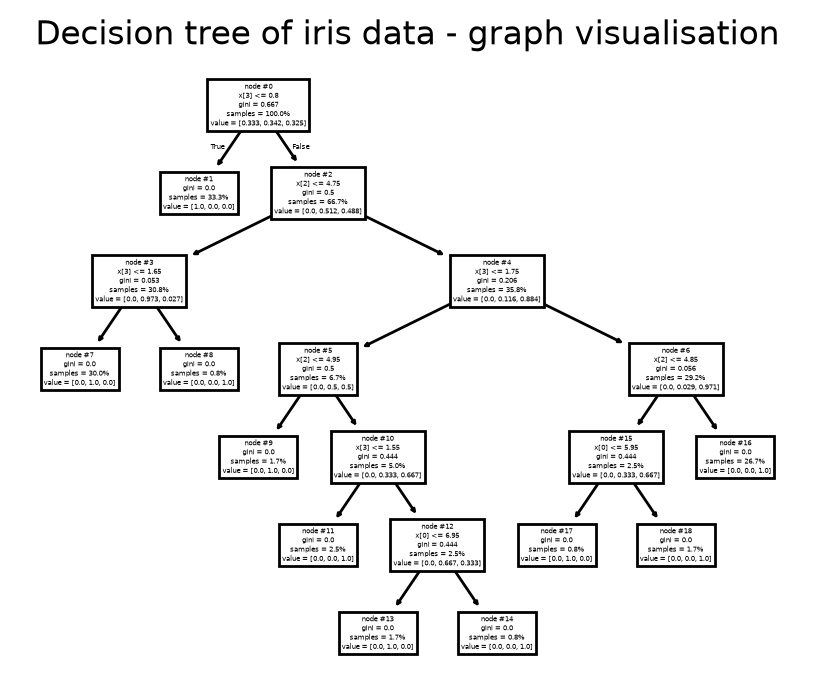

In [32]:
plt.figure(figsize=(5,4), dpi=200)
tree.plot_tree(clf, proportion=True, node_ids=True)
plt.title(f"Decision tree of iris data - graph visualisation")
plt.show()

What can be seen here?
 - graph visualises trained tree - how algortihm decides on which type of iris it is
 - each "deciding" block (a block having 2 arrows coming out of it) contains "decision rule" like `x[3]<=0.8`
 - each terminal block ends in conclusion (ex. `value = [0, 0, 1]` )

In [33]:
clf.feature_importances_

array([0.03334028, 0.        , 0.38926487, 0.57739485])

In [34]:
clf.criterion

'gini'

### Finding optimal structure using GridSearch

In [35]:
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.model_selection import GridSearchCV

# Load the Iris dataset
#iris = load_iris()
#X = iris.data  # Features
#y = iris.target  # Target species

# Split the dataset into training and testing sets
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Define the decision tree classifier
clf = DecisionTreeClassifier()

# Fit the model
clf.fit(X_train, y_train)

# Check feature importances
print("Feature importances:", clf.feature_importances_)

# Hyperparameter tuning using GridSearchCV
param_grid = {
    'max_depth': [None, 1, 2, 3, 4, 5, 10, 15],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 3, 4, 5]
}

grid_search = GridSearchCV(clf, param_grid, cv=5)
grid_search.fit(X_train, y_train)

# Get the best model
best_clf = grid_search.best_estimator_
print(f"Best depth = {best_clf.get_depth()},\n min samples split = {best_clf.min_samples_split},\n min leaf = {best_clf.min_samples_leaf}\n")

# Check feature importances of the best model
print("Best model feature importances:", best_clf.feature_importances_)


Feature importances: [0.03334028 0.         0.38926487 0.57739485]
Best depth = 4,
 min samples split = 5,
 min leaf = 3

Best model feature importances: [0.00601411 0.         0.95495215 0.03903374]


...so best decision tree looks like this:

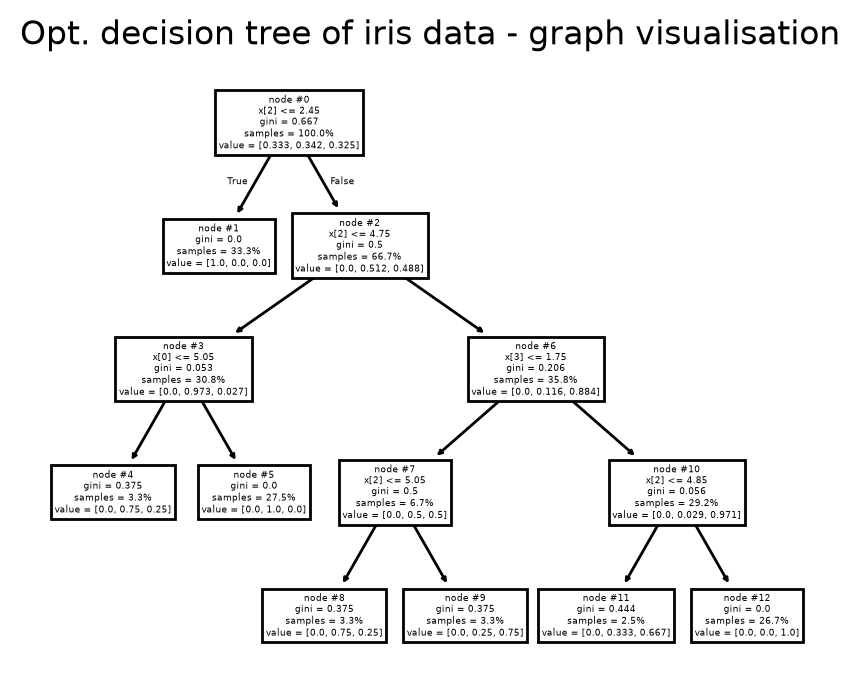

In [36]:
plt.figure(figsize=(5,4), dpi=200)
tree.plot_tree(best_clf, proportion=True, node_ids=True)
plt.title(f"Opt. decision tree of iris data - graph visualisation")
plt.show()

# Regression (`scikit-learn` and famous `diabetes` dataset)

In [47]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

In [48]:
# Load continuous target dataset
diabetes = load_diabetes()
X = diabetes.data
y = diabetes.target
feature_names = diabetes.feature_names

# Convert to DataFrame for inspection
df = pd.DataFrame(X, columns=feature_names)
df['target'] = y
df.head()

,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0


In [57]:
# Split dataset (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Instantiate DecisionTreeRegressor
# Default criterion is 'squared_error' (Variance Reduction / MSE)
reg = DecisionTreeRegressor(max_leaf_nodes=50, random_state=42)

# Train the regressor
reg.fit(X_train, y_train)


,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",50
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_feature

In [66]:
# Predict on test data
y_pred = reg.predict(X_test)

# Compute metrics
mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)

print(f"MSE:  {mse:.2f}")
print(f"MAE:  {mae:.2f}")

MSE:  3827.99
MAE:  47.37


In [65]:
sample_id = 5
X_test_sample = X_test[sample_id].reshape(1, -1)
y_test_sample = y_test[sample_id]
pred_sample = reg.predict(X_test_sample)[0]

print(f"True Target:      {y_test_sample:.1f}")
print(f"Predicted Target: {pred_sample:.1f}")


True Target:      84.0
Predicted Target: 81.4


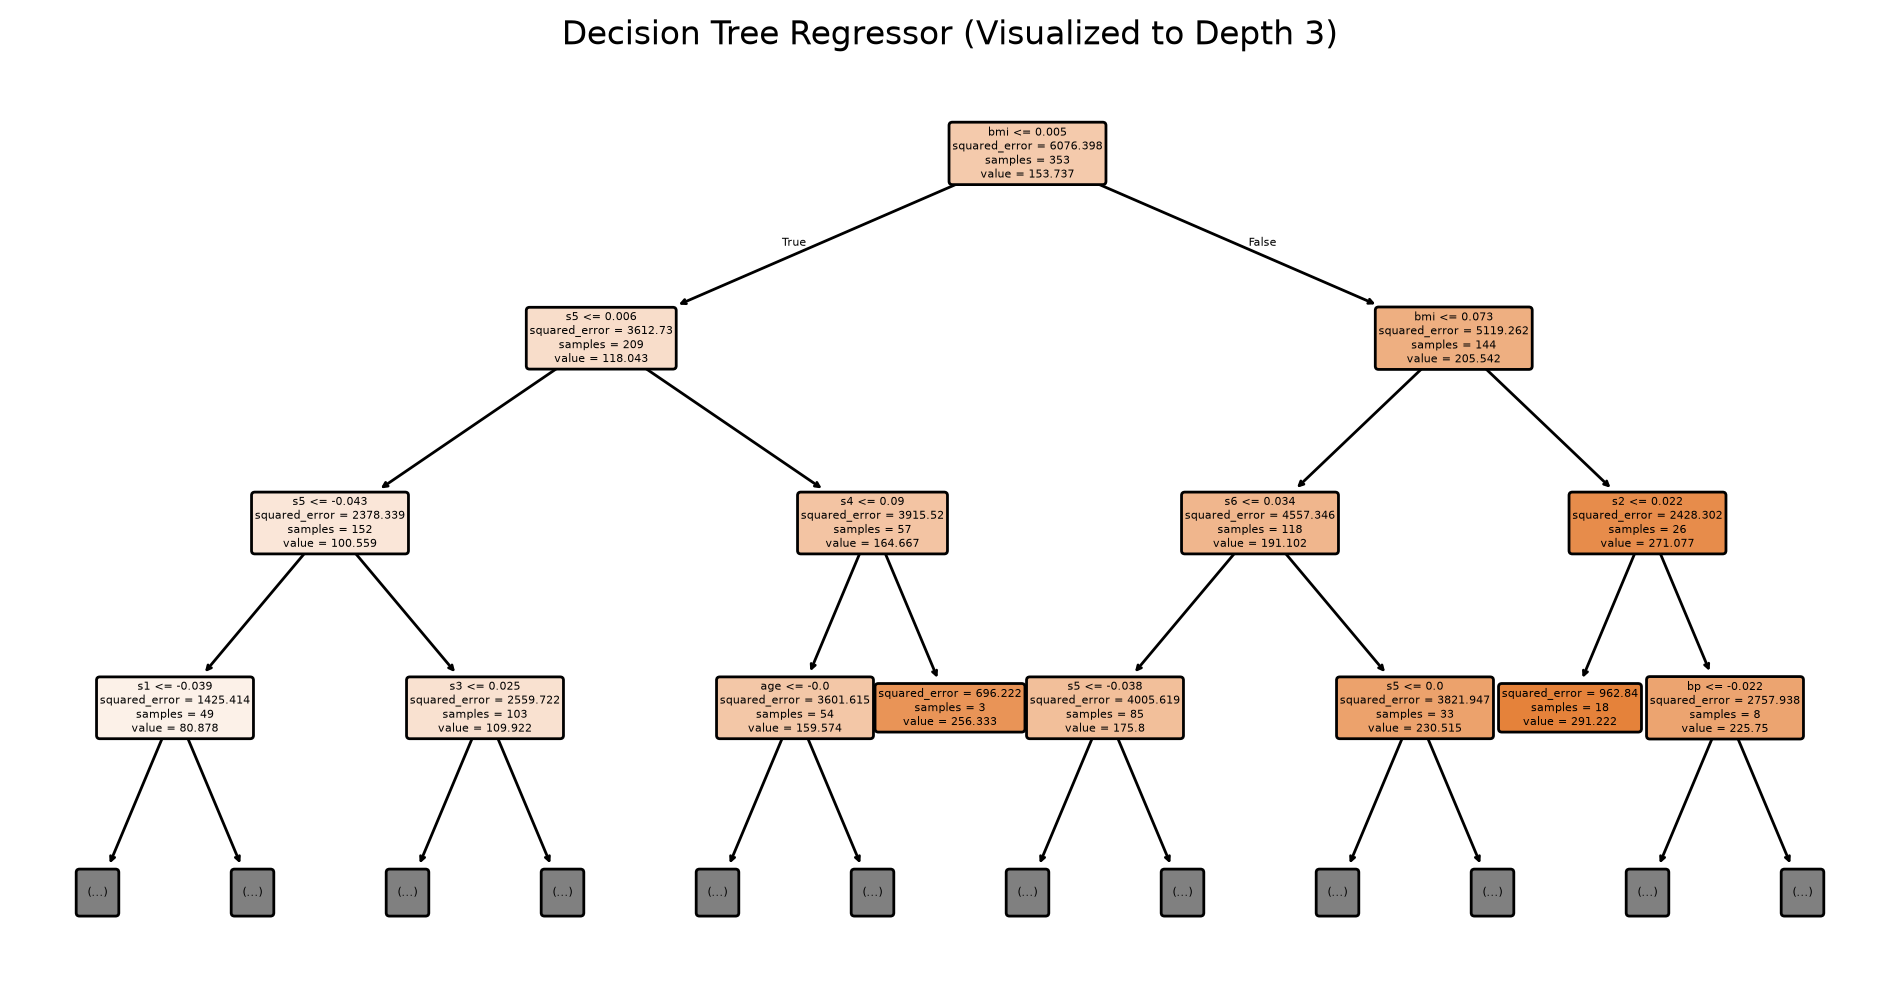

In [60]:
plt.figure(figsize=(12, 6), dpi=200)
plot_tree(
    reg,
    max_depth=3,  # Truncate visual depth to maintain legibility
    feature_names=feature_names,
    filled=True,
    rounded=True
)
plt.title("Decision Tree Regressor (Visualized to Depth 3)")
plt.show()


In [54]:
importances = pd.Series(reg.feature_importances_, index=feature_names)
print("Feature Importances:\n", importances.sort_values(ascending=False))

Feature Importances:
 bmi    0.438978
s5     0.161497
s1     0.081814
bp     0.063737
age    0.058799
s3     0.056809
s6     0.055992
s2     0.050606
s4     0.027400
sex    0.004368
dtype: float64


In [56]:
# Constrain the search to realistic pruning boundaries
param_grid = {
    'max_depth': [2, 3, 4, 5, 6],
    'min_samples_split': [5, 10, 20, 30],
    'min_samples_leaf': [2, 5, 10, 15]
}

grid_search = GridSearchCV(
    estimator=DecisionTreeRegressor(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)
grid_search.fit(X_train, y_train)

best_reg = grid_search.best_estimator_

# Correct parameter reporting (avoiding the duplicate min_samples_split bug)
print(f"Best Depth:             {best_reg.get_depth()}")
print(f"Best min_samples_split: {best_reg.min_samples_split}")
print(f"Best min_samples_leaf:  {best_reg.min_samples_leaf}")
print(f"Best CV MSE:            {-grid_search.best_score_:.2f}")

# Final validation on the unseen test set
y_test_pred_best = best_reg.predict(X_test)
print(f"Optimized Test MSE:     {mean_squared_error(y_test, y_test_pred_best):.2f}")


Best Depth:             2
Best min_samples_split: 5
Best min_samples_leaf:  2
Best CV MSE:            3774.45
Optimized Test MSE:     3735.50


## Sources (useful ones):
 - [IBM website](https://www.ibm.com/think/topics/decision-trees)
 - [inspiring Stack Exchange Q&A](https://stats.stackexchange.com/questions/94511/difference-between-bayes-network-neural-network-decision-tree-and-petri-nets)
 - [Scikit-learn tutorials](https://scikit-learn.org/1.6/auto_examples/tree/plot_unveil_tree_structure.html#sphx-glr-auto-examples-tree-plot-unveil-tree-structure-py)
